In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from scipy.optimize import fsolve

# Load shared POLDER style 
for _base in [Path.cwd(), *Path.cwd().parents]:
    _cand = _base / "templates" / "polder.mplstyle"
    if _cand.exists():
        plt.style.use(str(_cand))
        break

TEAL      = "#00A39B"   # stable equilibria / primary
DARK_TEAL = "#006661"   # axes, titles, equilibrium markers
CORAL     = "#E8633A"   # unstable / intervention / warning
BLUE      = "#0A4D9E"
SLATE     = "#5F6B7A"

print("ready")

ready


Set parameters and define rate of change f(X)=dX/dt and the potential function V(X) to create the landscape.

In [3]:
"""
Input parameters
----------------
X = population density
K = carrying capacity
c = maximum harvest rate    c=1 for high resilience, c=2.6 for low resilience
"""

K=10
c_low=2.6
c_high=1

def f(X,K,c):
    """f(X)=dX/dt"""
    return X*(1-X/K)-c*(X**2/(X**2+1))

def V(X,K,c):
    """V(x)=-∫f(X)dX is the potential landscape"""
    return -(0.5*X**2 - (1/(3*K))*X**3 - c*(X - np.arctan(X))) #integral of f(X) which I let wolfram alpha calculate for me


Plot landscape functions, corresponding to figure 1.a and figure 1.d

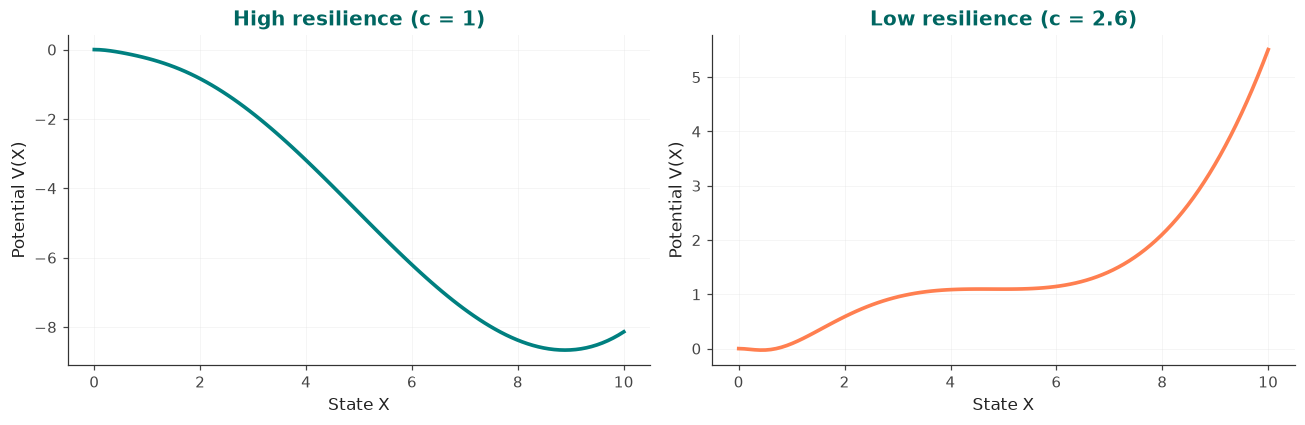

In [4]:
X = np.linspace(0,10,100)

V_high = V(X,K,c_high)
V_low = V(X,K,c_low)


#plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

#high resilience landscape
ax1.plot(X, V_high, color="TEAL", lw=2.4)
ax1.set_title("High resilience (c = 1)")
ax1.set_xlabel("State X")
ax1.set_ylabel("Potential V(X)")
ax1.grid(alpha=0.3)

#low resilience landscape
ax2.plot(X, V_low, color="CORAL", lw=2.4)
ax2.set_title("Low resilience (c = 2.6)")
ax2.set_xlabel("State X")
ax2.set_ylabel("Potential V(X)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

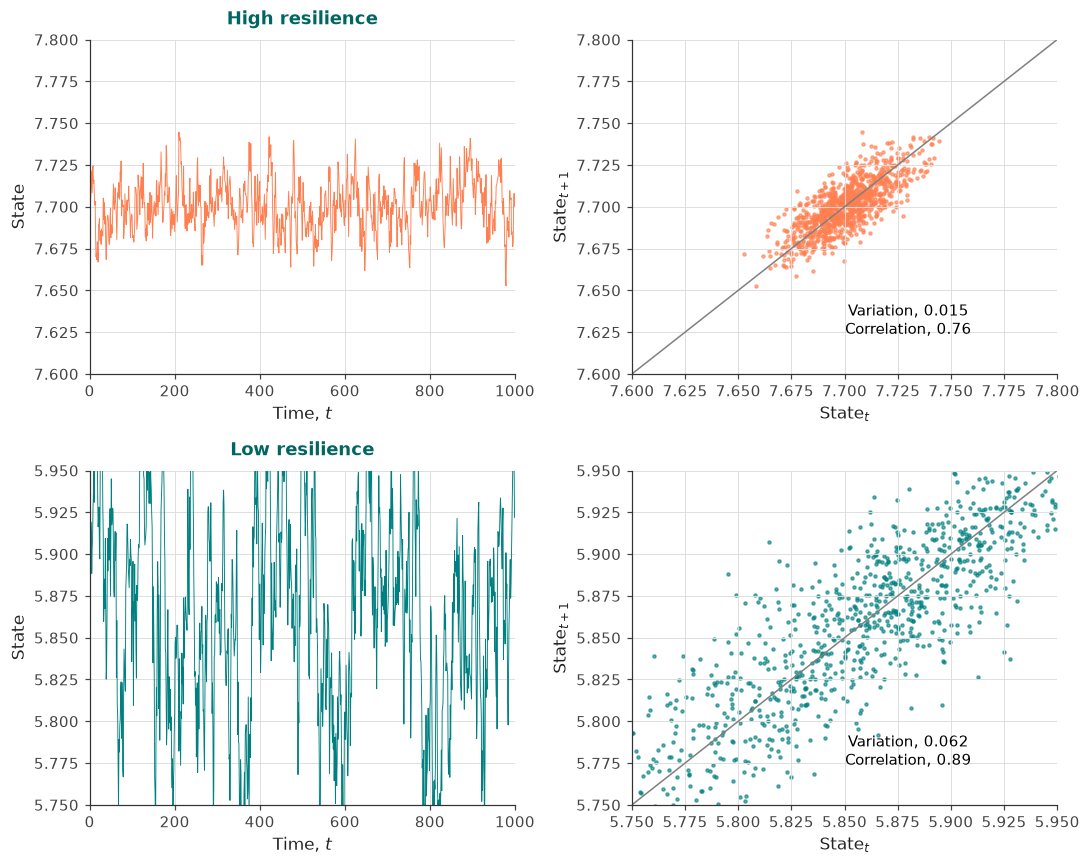

In [5]:
# Random seed for reproducibility
np.random.seed(42)

# Time from 0 to 1000
t_steps = 1000
time = np.arange(t_steps)

"""
1. High resilience
"""
# Autocorrelation coefficient
gamma_high = 0.76
# Noise magnitude
sigma_high = 0.010

# State over time
state_high = np.zeros(t_steps)
state_high[0] = 7.70  
for t in range(1, t_steps):
    state_high[t] = 7.70 + gamma_high * (state_high[t-1] - 7.70) + np.random.normal(0, sigma_high)

"""
2. Low resilience
"""
# Autocorrelation coefficient (here it takes longer to return to the equilibrium)
gamma_low = 0.90
# Noise magnitude (here it is larger than in the high resilience case)
sigma_low = 0.028

# State over time
state_low = np.zeros(t_steps)
state_low[0] = 5.845
for t in range(1, t_steps):
    state_low[t] = 5.845 + gamma_low * (state_low[t-1] - 5.845) + np.random.normal(0, sigma_low)

"""
Calculation of metrics
"""
# Lag-1 autocorrelation
x_t_h, x_t1_h = state_high[:-1], state_high[1:]
x_t_l, x_t1_l = state_low[:-1], state_low[1:]

# Variation as standard deviation (s.d.)
variation_h = np.std(state_high)
corr_h = np.corrcoef(x_t_h, x_t1_h)[0, 1]

variation_l = np.std(state_low)
corr_l = np.corrcoef(x_t_l, x_t1_l)[0, 1]

""" 
Figures
"""
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# High resilience (left one - state over time)
ax_b = axes[0, 0]
ax_b.plot(time, state_high, color='coral', lw=0.6)
ax_b.set_title('High resilience', fontsize=12, fontweight='bold', pad=10)
ax_b.set_ylabel('State')
ax_b.set_xlabel('Time, $t$')
ax_b.set_ylim(7.60, 7.80)
ax_b.set_xlim(0, 1000)

# High resilience (right one - lag-1 autocorrelation)
ax_c = axes[0, 1]
ax_c.scatter(x_t_h, x_t1_h, color='coral', s=4, alpha=0.6)
ax_c.plot([7.60, 7.80], [7.60, 7.80], color='gray', lw=1)
ax_c.set_xlim(7.60, 7.80)
ax_c.set_ylim(7.60, 7.80)
ax_c.set_ylabel('State$_{t+1}$')
ax_c.set_xlabel('State$_t$')
ax_c.text(0.65, 0.12, f'Variation, {variation_h:.3f}\nCorrelation, {corr_h:.2f}', 
          transform=ax_c.transAxes, fontsize=10, ha='center')

# Low resilience (left one - state over time)
ax_e = axes[1, 0]
ax_e.plot(time, state_low, color='teal', lw=0.6)
ax_e.set_title('Low resilience', fontsize=12, fontweight='bold', pad=10)
ax_e.set_ylabel('State')
ax_e.set_xlabel('Time, $t$')
ax_e.set_ylim(5.75, 5.95)
ax_e.set_xlim(0, 1000)

# Low resilience (right one - lag-1 autocorrelation)
ax_f = axes[1, 1]
ax_f.scatter(x_t_l, x_t1_l, color='teal', s=4, alpha=0.6)
ax_f.plot([5.75, 5.95], [5.75, 5.95], color='gray', lw=1)
ax_f.set_xlim(5.75, 5.95)
ax_f.set_ylim(5.75, 5.95)
ax_f.set_ylabel('State$_{t+1}$')
ax_f.set_xlabel('State$_t$')
ax_f.text(0.65, 0.12, f'Variation, {variation_l:.3f}\nCorrelation, {corr_l:.2f}', 
          transform=ax_f.transAxes, fontsize=10, ha='center')

plt.tight_layout()
plt.show()

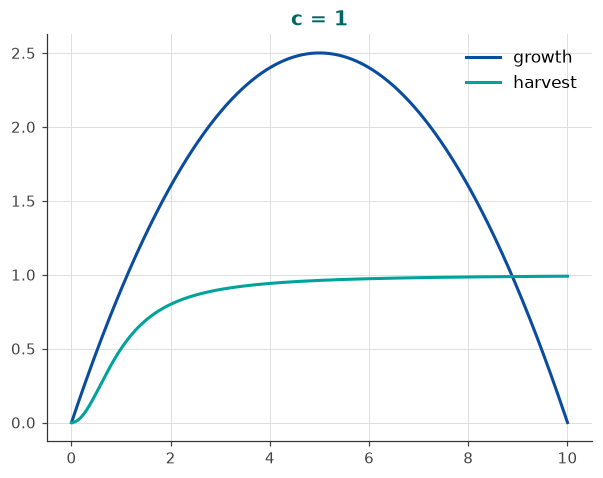

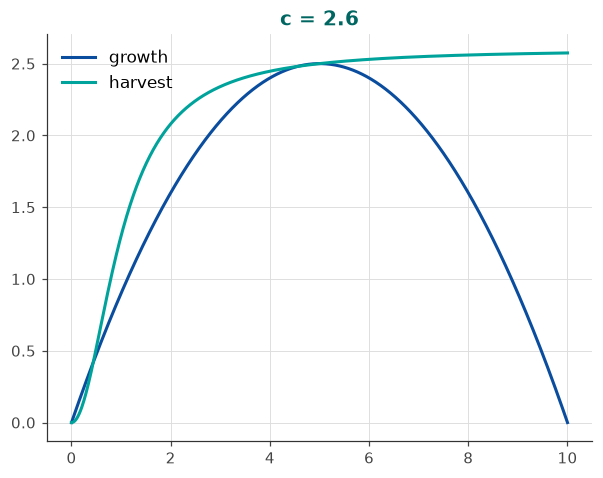

Quantitative check of the model

In [16]:
#finding the roots of the function f(X) = 0 to find the equilibria

X_high = fsolve(f, 7.7, args=(K, c_high))[0]
X_low = fsolve(f, 5.85, args=(K, c_low))[0]

def stability(X_eq,K,c):
    """calculate stability of equilibria"""
    eps = 1e-6 #small perturbation
    f_eq = 1-(2*X_eq)/K - c*(2*X_eq)/((X_eq**2 + 1)**2)
    return "stable" if f_eq < 0 else "unstable"

print(f"Equilibrium for c = {c_high}: X = {X_high:.4f} and is {stability(X_high,K,c_high)}")
print(f"Equilibrium for c = {c_low}: X = {X_low:.4f} and is {stability(X_low,K,c_low)}")

Equilibrium for c = 1: X = 8.8891 and is stable
Equilibrium for c = 2.6: X = 5.0000 and is stable


Phase line plot based on equilibria

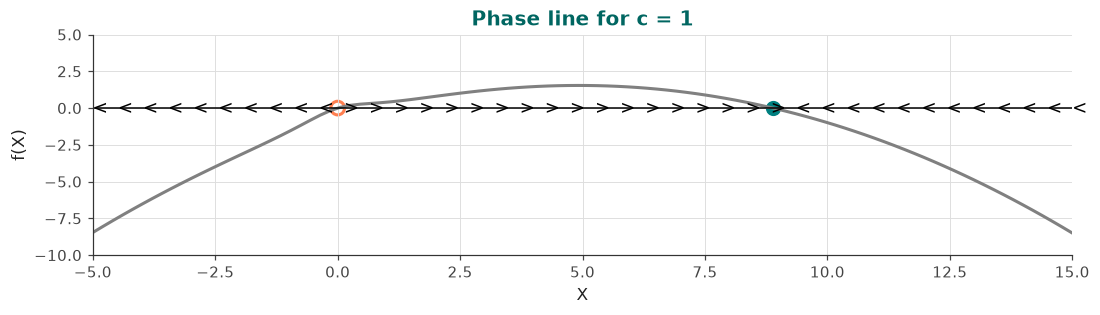

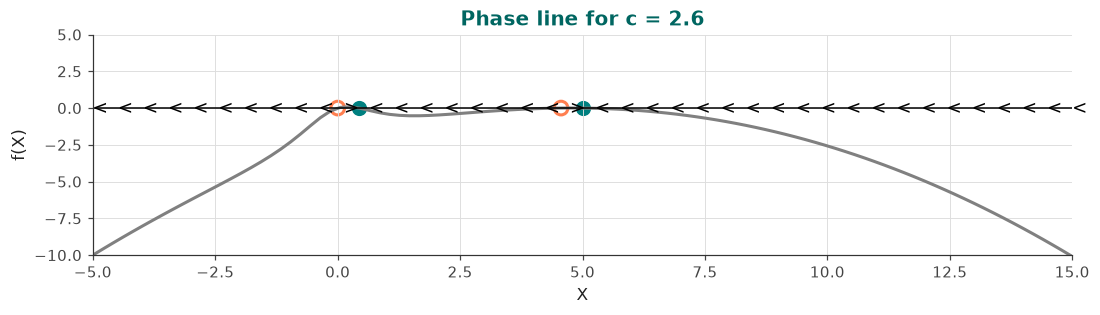

In [23]:
def phase_line(K,c,equilibria):
    """phase line plot for different values of c"""
    x_values = np.linspace(-5, 15, 100)
    f_plot = f(x_values, K, c)

    plt.figure(figsize=(10, 3))
    plt.plot(x_values, f_plot, color='grey', label="f(x)")
    plt.axhline(0, color='black', linewidth=1)

    for eq in equilibria:
        st = stability(eq, K, c)
        if st == "stable":
            plt.scatter(eq, 0, color="TEAL", s=80)  #stable point, filled dot
        else:
            plt.scatter(eq, 0, facecolors="none", edgecolors="CORAL", s=80, linewidth=2)  #unstable point, open dot

    #this puts the arrows on the x-axis
    for x in np.linspace(-5, 15, 40):
        if f(x, K, c) >= 0:
            plt.annotate(">", (x, 0), va='center', fontsize='12')
        else:
            plt.annotate("<", (x, 0), va='center', fontsize='12')
    
    plt.title(f"Phase line for c = {c}")
    plt.xlabel("X")
    plt.ylabel("f(X)")
    plt.ylim(-10, 5)
    plt.xlim(-5, 15)   
    plt.tight_layout()
    plt.show()

X_collapsed = fsolve(f, 0.4, args=(K, c_low))[0]   # 0.44
X_tipping = fsolve(f, 4.5, args=(K, c_low))[0]     # 4.56
phase_line(K, c_high, [0, X_high])
phase_line(K, c_low, [0,X_collapsed, X_tipping, X_low])


Plot variance, corresponding to figure 1.b and figure 1.e

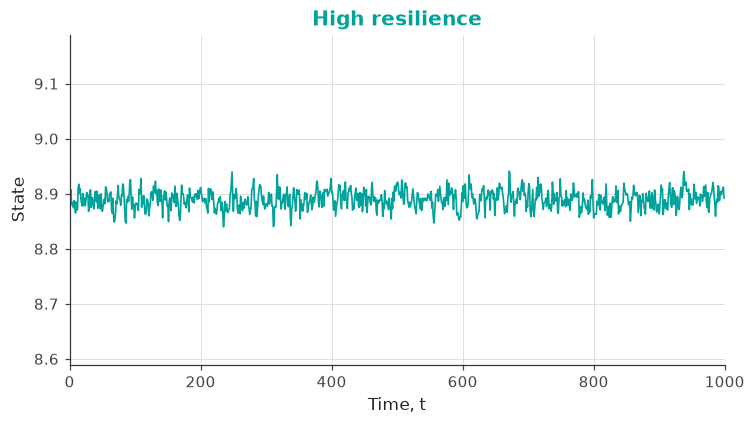

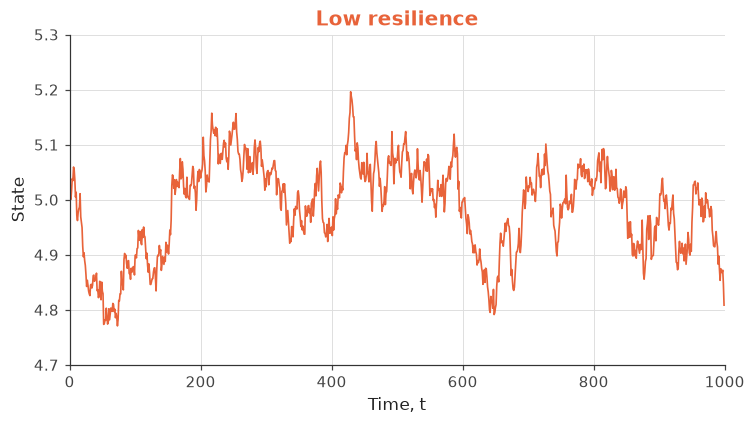

In [10]:
"""
Input parameters
Based  on the mathematical equilibria found above, we can set the initial conditions for the simulations
----------------
X0 = initital condition
"""

T = 100000 #total time (100,000 x 0.01 = 1000), better visualisation of the time series
dt = 0.01 #timestep
X_low = 5.00 #equilibrium for c=2.6
X_high = 8.8891 #equilibrium for c=1
noise = 0.02 
rng = np.random.default_rng(40) 

def simulate(c, X0):
    """Euler-Maruyama"""
    X = np.zeros(T)
    X[0] = X0
    
    for t in range(T-1):
        X[t + 1] = X[t] + f(X[t],K,c) * dt + noise*np.sqrt(dt)*rng.normal()
    return X[::100]  # Return every 100th value for visualization

high_resilience = simulate(c_high, X_high)
low_resilience = simulate(c_low, X_low)

#figure 1b: high resilience
plt.figure(figsize=(7, 4))
plt.plot(high_resilience, color=TEAL, lw=1.1)
plt.title("High resilience", color=TEAL)
plt.ylabel("State")
plt.xlabel("Time, t")
plt.ylim(X_high - 0.3, X_high + 0.3)   #y-axis as in the paper
plt.xlim(0, 1000)   #x-axis as in the paper
plt.tight_layout()
plt.show()

#figure 1e: low resilience
plt.figure(figsize=(7, 4))
plt.plot(low_resilience, color=CORAL, lw=1.1)
plt.title("Low resilience", color=CORAL)
plt.ylabel("State")
plt.xlabel("Time, t")
plt.ylim(X_low - 0.3, X_low + 0.3) #y-axis as in the paper
plt.xlim(0, 1000)   
plt.tight_layout()
plt.show()

High resilience: Variation (s.d.) = 0.0166, Lag-1 autocorrelation = 0.4824
Low resilience: Variation (s.d.) = 0.0833, Lag-1 autocorrelation = 0.9723


<function matplotlib.pyplot.show(close=None, block=None)>

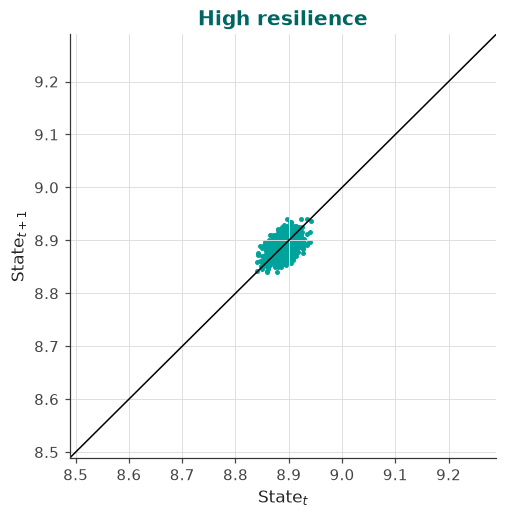

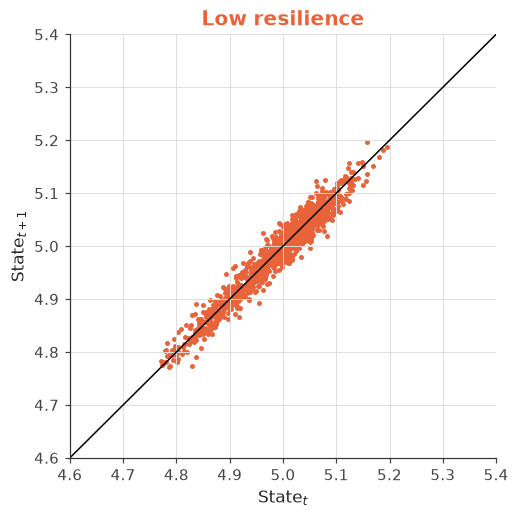

In [11]:
"""
high resilieve variance and lag-1 autocorrelation
"""
sd_high = np.std(high_resilience)
corr_high = np.corrcoef(high_resilience[:-1], high_resilience[1:])[0, 1]
print(f"High resilience: Variation (s.d.) = {sd_high:.4f}, Lag-1 autocorrelation = {corr_high:.4f}")

plt.figure(figsize=(5,5))
plt.scatter(high_resilience[:-1], high_resilience[1:], color=TEAL, s=5)
lims = (X_high - 0.4), (X_high + 0.4)
plt.plot(lims, lims, color='black', lw=1)
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("State$_t$")
plt.ylabel("State$_{t+1}$")
plt.title("High resilience")
plt.show

"""
low resilience
"""
sd_low = np.std(low_resilience)
corr_low = np.corrcoef(low_resilience[:-1], low_resilience[1:])[0, 1]
print(f"Low resilience: Variation (s.d.) = {sd_low:.4f}, Lag-1 autocorrelation = {corr_low:.4f}")

plt.figure(figsize=(5,5))
plt.scatter(low_resilience[:-1], low_resilience[1:], color=CORAL, s=5)
lims = (X_low - 0.4), (X_low + 0.4)
plt.plot(lims, lims, color='black', lw=1)
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("State$_t$")
plt.ylabel("State$_{t+1}$")
plt.title("Low resilience", color=CORAL)
plt.show

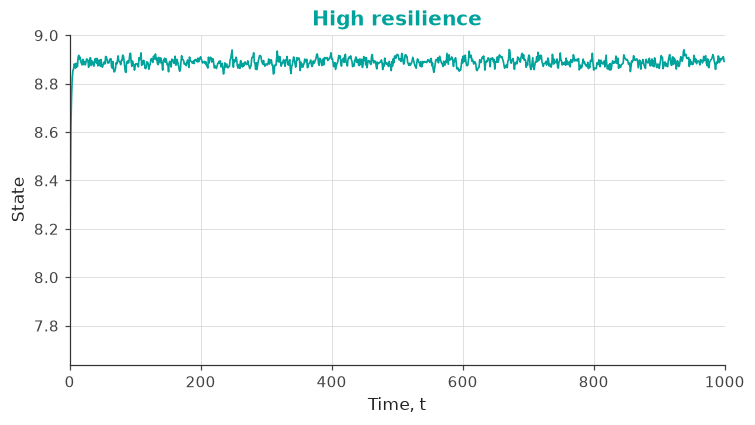

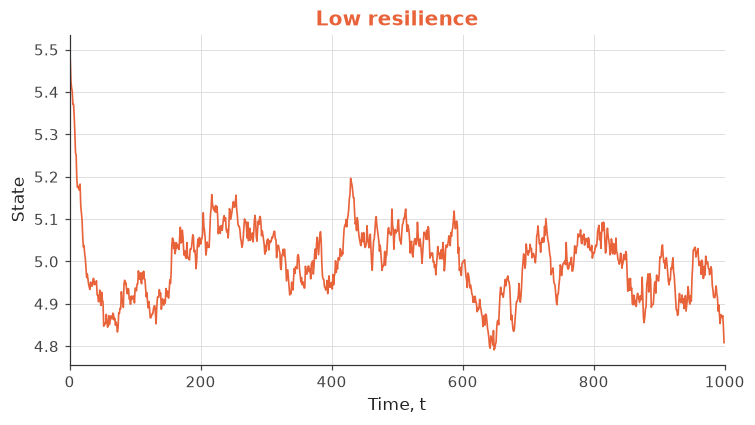

In [12]:
"""
Input parameters 
----------------
X0 = initital condition
"""

T = 100000 #total time (100,000 x 0.01 = 1000), better visualisation of the time series
dt = 0.01 #timestep
X_low = 5.5 #equilibrium for c=2.6
X_high = 7.7 #equilibrium for c=1 
noise = 0.02 
rng = np.random.default_rng(40) 

def simulate(c, X0):
    """Euler-Maruyama"""
    X = np.zeros(T)
    X[0] = X0
    
    for t in range(T-1):
        X[t + 1] = X[t] + f(X[t],K,c) * dt + noise*np.sqrt(dt)*rng.normal()
    return X[::100]  # Return every 100th value for visualization

high_resilience = simulate(c_high, X_high)
low_resilience = simulate(c_low, X_low)

#figure 1b: high resilience
plt.figure(figsize=(7, 4))
plt.plot(high_resilience, color=TEAL, lw=1.1)
plt.title("High resilience", color=TEAL)
plt.ylabel("State")
plt.xlabel("Time, t")
   #y-axis as in the paper
plt.xlim(0, 1000)   #y-axis as in the paper

plt.tight_layout()
plt.show()

#figure 1e: low resilience
plt.figure(figsize=(7, 4))
plt.plot(low_resilience, color=CORAL, lw=1.1)
plt.title("Low resilience", color=CORAL)
plt.ylabel("State")
plt.xlabel("Time, t")
plt.xlim(0, 1000)   
plt.tight_layout()
plt.show()